# Генерация изображений домашних животных

В этом ноутбуке два способа генерации:

1. **DCGAN** — генеративно-состязательная сеть, которую мы сами обучаем с нуля на лицах животных из датасета Pet Faces (64×64).
2. **VQGAN+CLIP** — ничего не обучаем: берём готовый декодер изображений (VQGAN) и готовую модель «картинка ↔ текст» (CLIP) и подбираем картинку под текстовое описание породы.

Ноутбук рассчитан на Google Colab с GPU (*Среда выполнения → Сменить среду выполнения → T4 GPU*). На CPU обе части будут работать очень медленно.

In [1]:
!wget -q -nc http://www.soshnikov.com/permanent/data/petfaces.tar.gz
!tar xfz petfaces.tar.gz

In [2]:
import math
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torchvision.utils import make_grid

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Устройство:', device)

Устройство: cuda


# Часть 1. DCGAN на лицах животных

## 1.1. Данные

Берём все изображения Pet Faces (породы здесь не нужны), уменьшаем до `IMG_SIZE × IMG_SIZE` и переводим в диапазон `[-1, 1]` — генератор заканчивается функцией `tanh`, которая выдаёт значения именно в этом диапазоне.

Датасет маленький (около 3 тыс. картинок), поэтому целиком кладём его в память видеокарты — так обучение идёт намного быстрее, чем с чтением файлов.

Чтобы попробовать разрешение 128×128, достаточно поменять `IMG_SIZE`: генератор и дискриминатор строятся под заданный размер автоматически.

Размер данных: (3211, 3, 64, 64) | диапазон: -1.0 ... 1.0


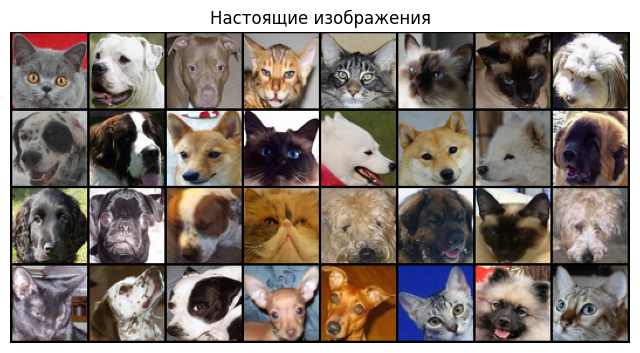

In [3]:
IMG_SIZE = 64      # 64 или 128 (степень двойки)
DATA_DIR = 'petfaces'

faces = []
for cls in sorted(os.listdir(DATA_DIR)):
    folder = os.path.join(DATA_DIR, cls)
    if not os.path.isdir(folder):
        continue
    for fname in sorted(os.listdir(folder)):
        try:
            img = Image.open(os.path.join(folder, fname)).convert('RGB')
        except Exception:
            continue
        faces.append(np.asarray(img.resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)))

# N x H x W x 3, uint8  ->  N x 3 x H x W, float в [-1, 1]
data = torch.from_numpy(np.stack(faces)).permute(0, 3, 1, 2).float().div(127.5).sub(1).to(device)
print('Размер данных:', tuple(data.shape), '| диапазон:', data.min().item(), '...', data.max().item())


def show(batch, title=None, nrow=8, size=8):
    """Рисует батч изображений из диапазона [-1, 1] в виде сетки."""
    grid = make_grid(batch.detach().cpu(), nrow=nrow, normalize=True, value_range=(-1, 1), padding=2)
    plt.figure(figsize=(size, size * math.ceil(len(batch) / nrow) / nrow + 0.4))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    if title:
        plt.title(title)
    plt.show()


show(data[torch.randperm(len(data))[:32]], 'Настоящие изображения')

## 1.2. Генератор и дискриминатор

Архитектура — классический [DCGAN](https://arxiv.org/abs/1511.06434).

**Генератор** превращает случайный вектор `z` (100 чисел) в картинку: начинает с карты 4×4 и каждой транспонированной свёрткой увеличивает её вдвое (4 → 8 → 16 → 32 → 64), уменьшая число каналов. Внутри — BatchNorm и ReLU, на выходе — `tanh`.

**Дискриминатор** — зеркальная обычная свёрточная сеть: каждая свёртка с шагом 2 уменьшает картинку вдвое, в конце одно число — оценка «настоящая / поддельная» (логит, без сигмоиды).

In [4]:
NZ = 100                                   # размер случайного вектора
N_STAGES = int(math.log2(IMG_SIZE)) - 2    # 64 -> 4 стадии, 128 -> 5
CHANNELS = [min(64 * 2 ** i, 512) for i in range(N_STAGES)]   # для 64: [64, 128, 256, 512]


class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        ch = CHANNELS[::-1]                                         # от широких слоёв к узким
        layers = [nn.ConvTranspose2d(NZ, ch[0], 4, 1, 0, bias=False),   # 1x1 -> 4x4
                  nn.BatchNorm2d(ch[0]), nn.ReLU(True)]
        for c_in, c_out in zip(ch[:-1], ch[1:]):                    # каждый блок удваивает размер
            layers += [nn.ConvTranspose2d(c_in, c_out, 4, 2, 1, bias=False),
                       nn.BatchNorm2d(c_out), nn.ReLU(True)]
        layers += [nn.ConvTranspose2d(ch[-1], 3, 4, 2, 1), nn.Tanh()]   # последний шаг: до IMG_SIZE
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        ch = CHANNELS
        layers = [nn.Conv2d(3, ch[0], 4, 2, 1), nn.LeakyReLU(0.2, True)]
        for c_in, c_out in zip(ch[:-1], ch[1:]):                    # каждый блок уменьшает размер вдвое
            layers += [nn.Conv2d(c_in, c_out, 4, 2, 1, bias=False),
                       nn.BatchNorm2d(c_out), nn.LeakyReLU(0.2, True)]
        layers += [nn.Conv2d(ch[-1], 1, 4, 1, 0)]                   # 4x4 -> 1x1
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).view(-1)


def init_weights(m):
    """Инициализация из статьи DCGAN: веса из нормального распределения с отклонением 0.02."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


G = Generator().to(device).apply(init_weights)
D = Discriminator().to(device).apply(init_weights)

z = torch.randn(4, NZ, 1, 1, device=device)
print('Выход генератора:', tuple(G(z).shape), '| выход дискриминатора:', tuple(D(G(z)).shape))
print(f'Параметров: G {sum(p.numel() for p in G.parameters()) / 1e6:.2f} млн, '
      f'D {sum(p.numel() for p in D.parameters()) / 1e6:.2f} млн')

Выход генератора: (4, 3, 64, 64) | выход дискриминатора: (4,)
Параметров: G 3.58 млн, D 2.77 млн


## 1.3. Обучение

На каждом шаге:

1. **Дискриминатор** учится отличать настоящие картинки (цель 1) от сгенерированных (цель 0).
2. **Генератор** учится обманывать дискриминатор: хочет, чтобы на его картинках дискриминатор отвечал 1.

Приёмы, которые помогают на маленьком датасете:

* **Одинаковые аугментации для настоящих и поддельных картинок** перед подачей в дискриминатор (идея [DiffAugment](https://arxiv.org/abs/2006.10738)): случайный сдвиг и случайная яркость. Дискриминатору труднее «запомнить» 3 тыс. картинок, а генератор при этом не учится рисовать сдвинутые картинки, потому что аугментация применяется к обоим источникам одинаково.
* Случайное зеркальное отражение настоящих картинок.
* **Сглаживание меток**: цель для настоящих картинок 0.9 вместо 1, чтобы дискриминатор не становился слишком уверенным.

In [5]:
def augment(x, max_shift=IMG_SIZE // 8):
    """Случайный сдвиг (общий для батча) и случайная яркость (своя для каждой картинки)."""
    dx, dy = torch.randint(0, 2 * max_shift + 1, (2,)).tolist()
    x = F.pad(x, [max_shift] * 4)                              # добавляем поля из нулей
    x = x[:, :, dy:dy + IMG_SIZE, dx:dx + IMG_SIZE]            # вырезаем окно исходного размера
    return x + (torch.rand(len(x), 1, 1, 1, device=x.device) - 0.5) * 0.4


EPOCHS = 200
BATCH = 64

opt_g = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()

fixed_z = torch.randn(64, NZ, 1, 1, device=device)    # один и тот же шум, чтобы следить за прогрессом
real_target = torch.full((BATCH,), 0.9, device=device)
fake_target = torch.zeros(BATCH, device=device)
ones = torch.ones(BATCH, device=device)

loss_history = {'D': [], 'G': []}
snapshots = {}
start = time.time()

for epoch in range(1, EPOCHS + 1):
    perm = torch.randperm(len(data), device=device)
    d_sum, g_sum, steps = 0.0, 0.0, 0
    for i in range(0, len(data) - BATCH + 1, BATCH):
        real = data[perm[i:i + BATCH]]
        flip = torch.rand(BATCH, 1, 1, 1, device=device) < 0.5
        real = torch.where(flip, real.flip(-1), real)
        fake = G(torch.randn(BATCH, NZ, 1, 1, device=device))

        # --- шаг дискриминатора (fake.detach(): градиент не идёт в генератор)
        loss_d = bce(D(augment(real)), real_target) + bce(D(augment(fake.detach())), fake_target)
        opt_d.zero_grad()
        loss_d.backward()
        opt_d.step()

        # --- шаг генератора
        loss_g = bce(D(augment(fake)), ones)
        opt_g.zero_grad()
        loss_g.backward()
        opt_g.step()

        d_sum += loss_d.item()
        g_sum += loss_g.item()
        steps += 1

    loss_history['D'].append(d_sum / steps)
    loss_history['G'].append(g_sum / steps)
    if epoch in (1, 10, 25, 50, 100, EPOCHS):
        G.eval()
        with torch.no_grad():
            snapshots[epoch] = G(fixed_z[:16]).cpu()
        G.train()
    if epoch % 20 == 0 or epoch == 1:
        print(f'эпоха {epoch:3d}/{EPOCHS}: loss D {d_sum / steps:.3f}, loss G {g_sum / steps:.3f} '
              f'({time.time() - start:.0f} с)')

эпоха   1/200: loss D 0.643, loss G 4.601 (5 с)
эпоха  20/200: loss D 1.261, loss G 1.663 (86 с)
эпоха  40/200: loss D 0.992, loss G 2.181 (176 с)
эпоха  60/200: loss D 1.084, loss G 1.703 (266 с)
эпоха  80/200: loss D 1.202, loss G 1.524 (356 с)
эпоха 100/200: loss D 1.172, loss G 1.429 (446 с)
эпоха 120/200: loss D 1.167, loss G 1.407 (536 с)
эпоха 140/200: loss D 1.150, loss G 1.390 (626 с)
эпоха 160/200: loss D 1.112, loss G 1.418 (716 с)
эпоха 180/200: loss D 1.173, loss G 1.485 (806 с)
эпоха 200/200: loss D 1.070, loss G 1.637 (896 с)


## 1.4. Результаты DCGAN

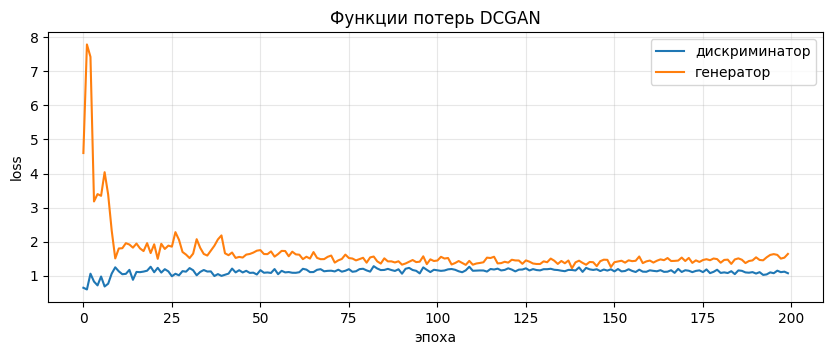

In [6]:
plt.figure(figsize=(10, 3.5))
plt.plot(loss_history['D'], label='дискриминатор')
plt.plot(loss_history['G'], label='генератор')
plt.xlabel('эпоха')
plt.ylabel('loss')
plt.title('Функции потерь DCGAN')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

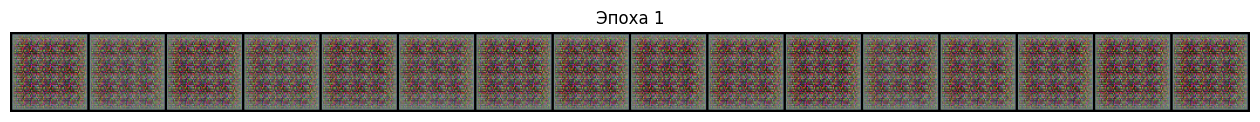

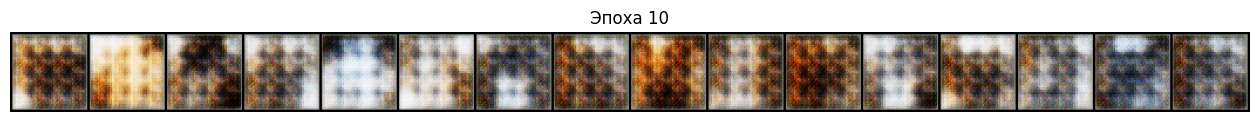

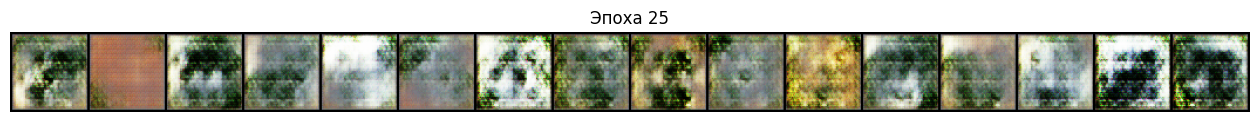

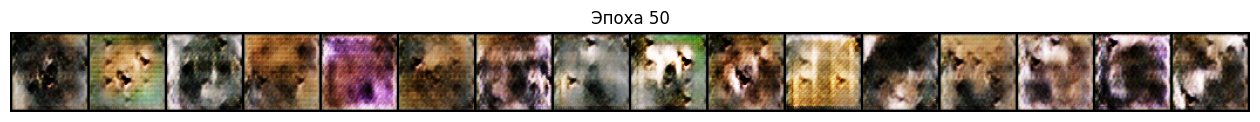

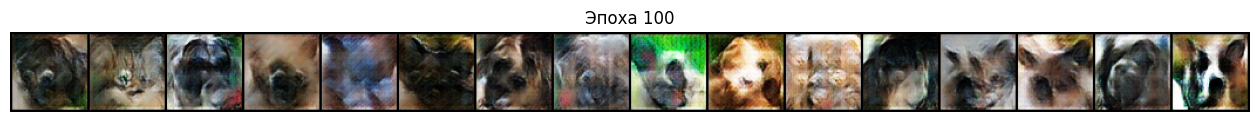

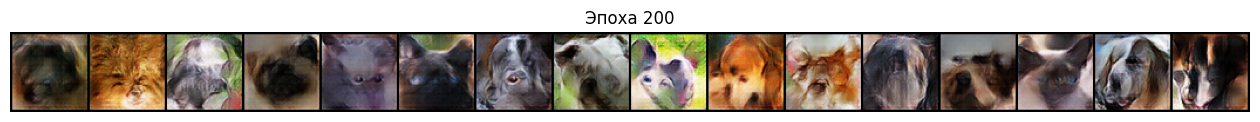

In [7]:
# Как менялись картинки для одного и того же шума по ходу обучения
for epoch, images in snapshots.items():
    show(images, f'Эпоха {epoch}', nrow=16, size=16)

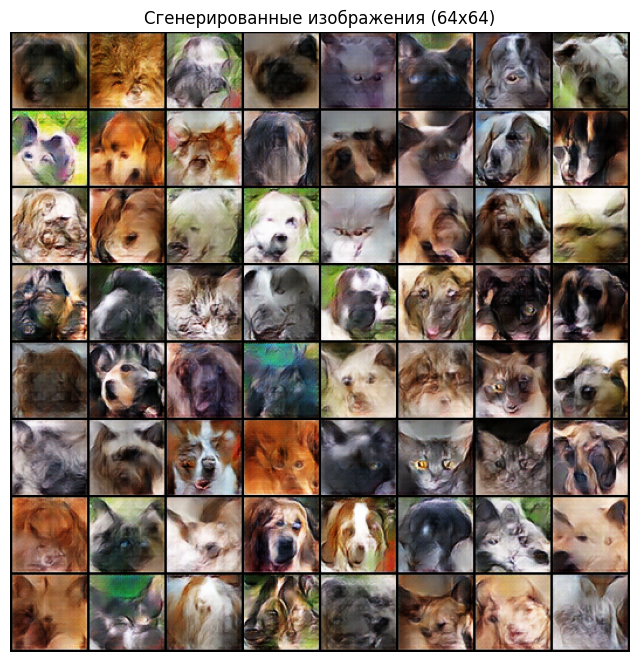

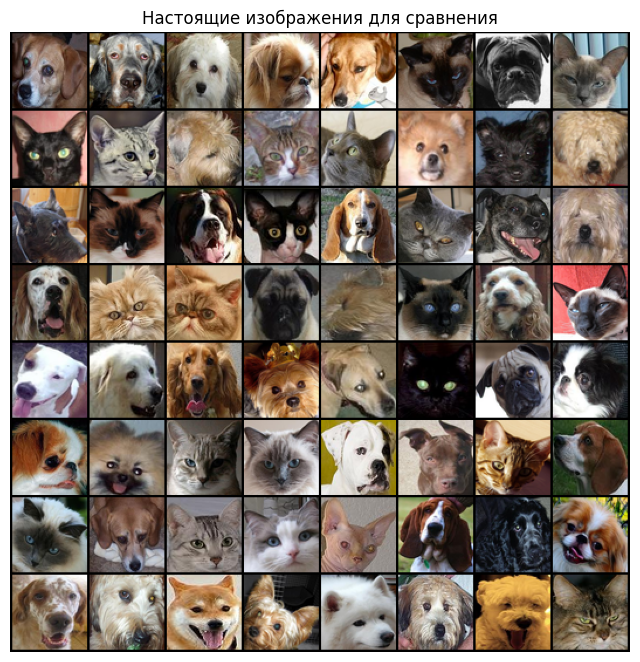

In [8]:
G.eval()
with torch.no_grad():
    generated = G(fixed_z)
show(generated, f'Сгенерированные изображения ({IMG_SIZE}x{IMG_SIZE})')
show(data[torch.randperm(len(data))[:64]], 'Настоящие изображения для сравнения')

### Интерполяция в скрытом пространстве

Берём два случайных вектора `z` и плавно переходим от одного к другому. Если генератор выучил осмысленное скрытое пространство, а не просто запомнил картинки, то промежуточные изображения тоже похожи на животных и меняются плавно.

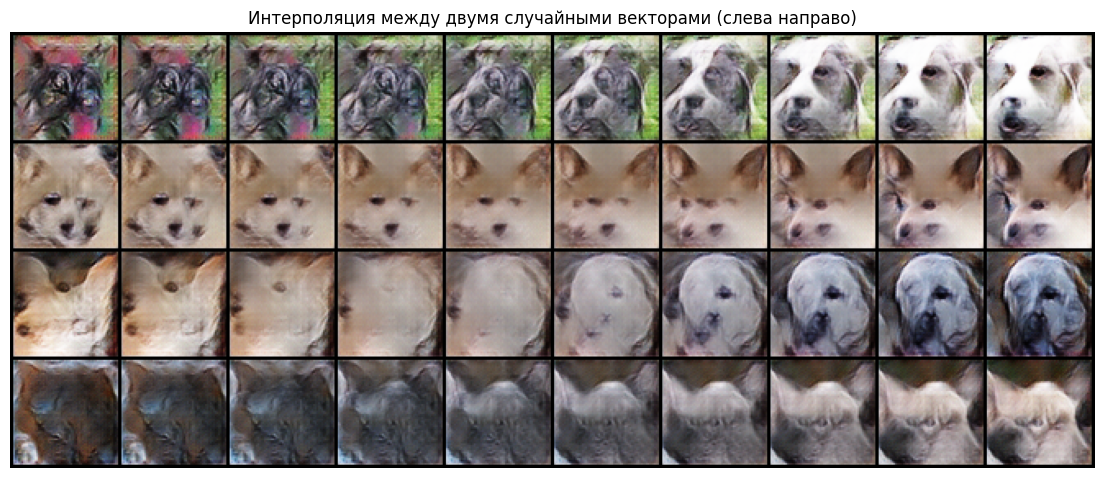

In [9]:
torch.manual_seed(1)
steps = torch.linspace(0, 1, 10, device=device).view(-1, 1, 1, 1)
rows = []
with torch.no_grad():
    for _ in range(4):
        z0, z1 = torch.randn(2, NZ, 1, 1, device=device)
        rows.append(G(z0 * (1 - steps) + z1 * steps))
show(torch.cat(rows), 'Интерполяция между двумя случайными векторами (слева направо)', nrow=10, size=14)

# Часть 2. VQGAN+CLIP

## 2.1. Идея

* **VQGAN** — автоэнкодер с дискретным «словарём» (codebook): картинка сжимается в небольшую карту скрытых векторов `z` (для картинки 256×256 это 16×16 векторов), а декодер по этой карте рисует картинку обратно.
* **CLIP** — умеет оценивать, насколько картинка соответствует тексту.

Генерация — это **оптимизация**, а не обучение: веса обеих сетей заморожены, меняется только `z`.

1. Начинаем со случайной карты `z`.
2. Декодируем её в картинку с помощью VQGAN.
3. Вырезаем из картинки несколько случайных фрагментов и кодируем их CLIP.
4. Считаем, насколько фрагменты далеки от текста промпта (1 − косинусная близость).
5. Градиентным шагом меняем `z` так, чтобы картинка стала ближе к тексту. Повторяем.

В качестве VQGAN используется предобученная модель из проекта [aMUSEd](https://huggingface.co/amused/amused-256) (сжатие в 16 раз, словарь из 8192 векторов), загружаемая через библиотеку `diffusers`. Оригинальный пакет `taming-transformers` давно не обновляется и не ставится на современные версии библиотек, а здесь всё загружается одной строкой.

In [10]:
!pip -q install diffusers git+https://github.com/openai/CLIP.git

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.2 MB/s eta 0:00:00


In [11]:
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'   # без виджетов загрузки: с ними ноутбук хуже отображается на GitHub

import clip
from diffusers import VQModel
from torchvision import transforms

# Обе модели заморожены: requires_grad_(False)
vqgan = VQModel.from_pretrained('amused/amused-256', subfolder='vqvae').to(device).eval().requires_grad_(False)
clip_model, _ = clip.load('ViT-B/32', device=device)
clip_model = clip_model.float().eval().requires_grad_(False)

DOWN = 2 ** (len(vqgan.config.block_out_channels) - 1)      # во сколько раз VQGAN сжимает картинку
codebook = vqgan.quantize.embedding.weight                  # словарь: N векторов размерности dim
print(f'VQGAN: сжатие в {DOWN} раз, словарь {tuple(codebook.shape)}')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
100%|████████████████████████████████████████| 338M/338M [00:03<00:00, 103MiB/s]


VQGAN: сжатие в 16 раз, словарь (8192, 64)


### Проверка VQGAN

Прежде чем генерировать, убеждаемся, что VQGAN работает как автоэнкодер: кодируем настоящие картинки и декодируем обратно. Модель принимает и выдаёт изображения в диапазоне `[0, 1]`.

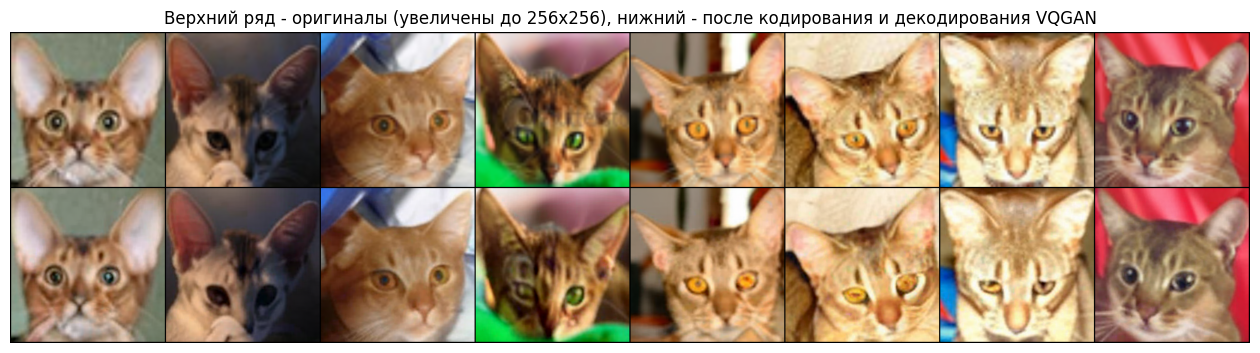

In [12]:
with torch.no_grad():
    originals = F.interpolate((data[:8] + 1) / 2, size=256, mode='bilinear', align_corners=False)
    reconstructed = vqgan(originals).sample.clamp(0, 1)

grid = make_grid(torch.cat([originals, reconstructed]).cpu(), nrow=8, padding=2)
plt.figure(figsize=(16, 4.3))
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.title('Верхний ряд - оригиналы (увеличены до 256x256), нижний - после кодирования и декодирования VQGAN')
plt.show()

## 2.2. Генерация по тексту

Три небольшие детали, без которых метод работает плохо:

* **Случайные фрагменты (cutouts).** CLIP принимает картинку 224×224. Если показывать ему всю картинку целиком, оптимизация находит «обманки» — шум, который CLIP считает похожим на текст. Поэтому на каждом шаге CLIP видит много случайных фрагментов разного размера (и их отражения), и картинка должна соответствовать тексту во всех них.
* **Квантование с пропуском градиента.** `vqgan.decode(z)` сначала заменяет каждый вектор `z` на ближайший вектор словаря. Эта операция недифференцируема, поэтому градиент пропускается сквозь неё без изменений (straight-through) — так уже сделано внутри модели.
* **Шаг оптимизации** задаётся относительно разброса значений словаря, чтобы не зависеть от масштаба скрытого пространства конкретной модели.

In [13]:
clip_normalize = transforms.Normalize((0.48145466, 0.4578275, 0.40821073),
                                      (0.26862954, 0.26130258, 0.27577711))


def make_cutouts(image, n=32, min_scale=0.4):
    """Вырезает n случайных квадратных фрагментов и приводит их к размеру входа CLIP (224x224)."""
    side = image.shape[-1]
    cuts = []
    for _ in range(n):
        size = int(side * torch.empty(1).uniform_(min_scale, 1.0).item())
        x0, y0 = torch.randint(0, side - size + 1, (2,)).tolist()
        cut = image[:, :, y0:y0 + size, x0:x0 + size]
        cuts.append(F.interpolate(cut, size=224, mode='bilinear', align_corners=False))
    cuts = torch.cat(cuts)
    flip = torch.rand(n, 1, 1, 1, device=image.device) < 0.5
    return torch.where(flip, cuts.flip(-1), cuts)


def decode(z):
    """Скрытая карта -> картинка в [0, 1]. Обрезка значений сделана так, чтобы градиент не обнулялся."""
    image = vqgan.decode(z).sample
    return image + (image.clamp(0, 1) - image).detach()


def generate(prompt, steps=300, size=256, lr_scale=0.1, seed=0):
    torch.manual_seed(seed)
    with torch.no_grad():
        text = F.normalize(clip_model.encode_text(clip.tokenize([prompt]).to(device)), dim=-1)

    # старт: случайные векторы словаря
    side = size // DOWN
    ids = torch.randint(0, len(codebook), (side * side,), device=device)
    z = codebook[ids].view(1, side, side, -1).permute(0, 3, 1, 2).clone().requires_grad_(True)
    optimizer = torch.optim.Adam([z], lr=lr_scale * codebook.std().item())

    losses = []
    for _ in range(steps):
        image = decode(z)
        features = F.normalize(clip_model.encode_image(clip_normalize(make_cutouts(image))), dim=-1)
        loss = (1 - features @ text.T).mean()       # 1 - косинусная близость, усреднённая по фрагментам
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    with torch.no_grad():
        return decode(z)[0].permute(1, 2, 0).cpu().numpy(), losses

### Один пример и ход оптимизации

Время генерации одной картинки: 174 с


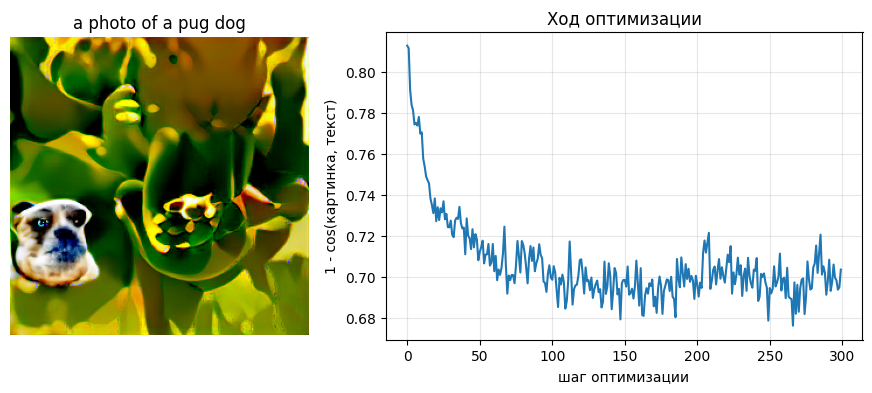

In [14]:
start = time.time()
image, losses = generate('a photo of a pug dog')
print(f'Время генерации одной картинки: {time.time() - start:.0f} с')

fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [1, 1.6]})
ax[0].imshow(image)
ax[0].axis('off')
ax[0].set_title('a photo of a pug dog')
ax[1].plot(losses)
ax[1].set_xlabel('шаг оптимизации')
ax[1].set_ylabel('1 - cos(картинка, текст)')
ax[1].set_title('Ход оптимизации')
ax[1].grid(alpha=0.3)
plt.show()

## 2.3. 7 пород собак и 7 пород кошек

In [15]:
dog_breeds = ['pug', 'beagle', 'samoyed', 'shiba inu', 'german shepherd', 'golden retriever', 'dalmatian']
cat_breeds = ['siamese', 'persian', 'sphynx', 'maine coon', 'bengal', 'british shorthair', 'russian blue']

prompts = ([f'a photo of a {breed} dog' for breed in dog_breeds]
           + [f'a photo of a {breed} cat' for breed in cat_breeds])

generated_pets, final_losses = [], []
start = time.time()
for n, prompt in enumerate(prompts, 1):
    image, losses = generate(prompt, seed=n)
    generated_pets.append(image)
    final_losses.append(losses[-1])
    print(f'[{n}/{len(prompts)}] {prompt}: loss {losses[0]:.3f} -> {losses[-1]:.3f} ({time.time() - start:.0f} с)')

[1/14] a photo of a pug dog: loss 0.816 -> 0.687 (172 с)
[2/14] a photo of a beagle dog: loss 0.801 -> 0.668 (344 с)
[3/14] a photo of a samoyed dog: loss 0.836 -> 0.674 (516 с)
[4/14] a photo of a shiba inu dog: loss 0.809 -> 0.683 (689 с)
[5/14] a photo of a german shepherd dog: loss 0.834 -> 0.701 (861 с)
[6/14] a photo of a golden retriever dog: loss 0.830 -> 0.678 (1033 с)
[7/14] a photo of a dalmatian dog: loss 0.799 -> 0.624 (1205 с)
[8/14] a photo of a siamese cat: loss 0.810 -> 0.682 (1378 с)
[9/14] a photo of a persian cat: loss 0.819 -> 0.662 (1550 с)
[10/14] a photo of a sphynx cat: loss 0.816 -> 0.684 (1722 с)
[11/14] a photo of a maine coon cat: loss 0.859 -> 0.707 (1895 с)
[12/14] a photo of a bengal cat: loss 0.848 -> 0.680 (2067 с)
[13/14] a photo of a british shorthair cat: loss 0.846 -> 0.632 (2239 с)
[14/14] a photo of a russian blue cat: loss 0.859 -> 0.689 (2411 с)


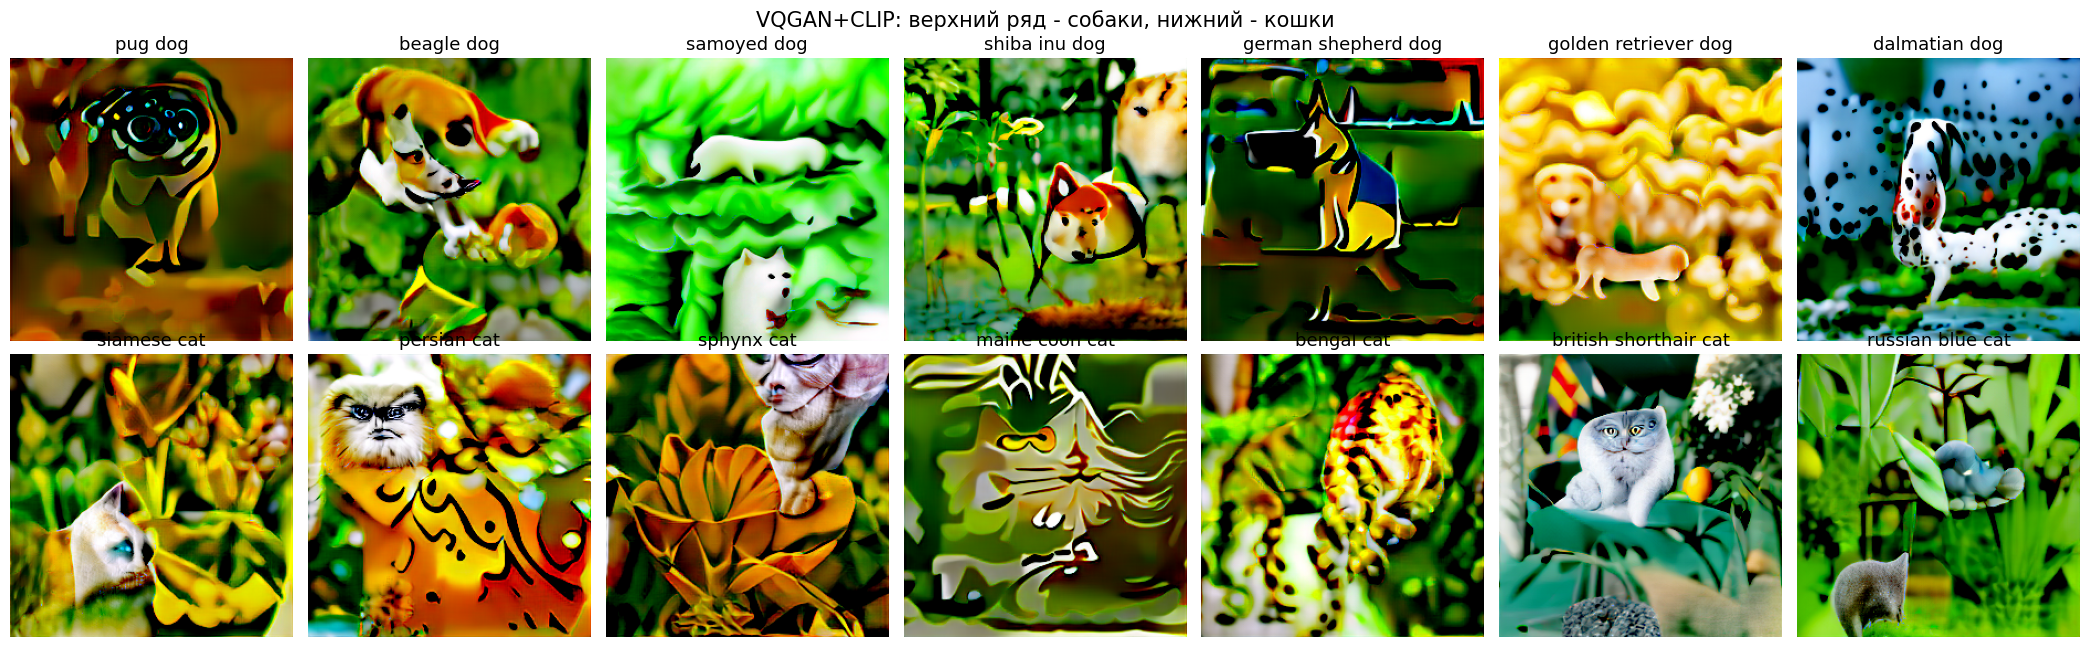

In [16]:
fig, ax = plt.subplots(2, 7, figsize=(21, 6.6))
for a, image, prompt in zip(ax.ravel(), generated_pets, prompts):
    a.imshow(image)
    a.axis('off')
    a.set_title(prompt.replace('a photo of a ', ''), fontsize=13)
plt.suptitle('VQGAN+CLIP: верхний ряд - собаки, нижний - кошки', fontsize=15)
plt.tight_layout()
plt.show()

### Проверка: узнаёт ли CLIP породы на сгенерированных картинках

Для каждой картинки считаем близость ко всем 14 промптам. Если генерация удалась, самые большие значения стоят на диагонали: картинка ближе всего к «своему» тексту. Это не независимая оценка качества (картинки и создавались так, чтобы нравиться этому же CLIP), но хорошая проверка того, что оптимизация сошлась и породы различимы.

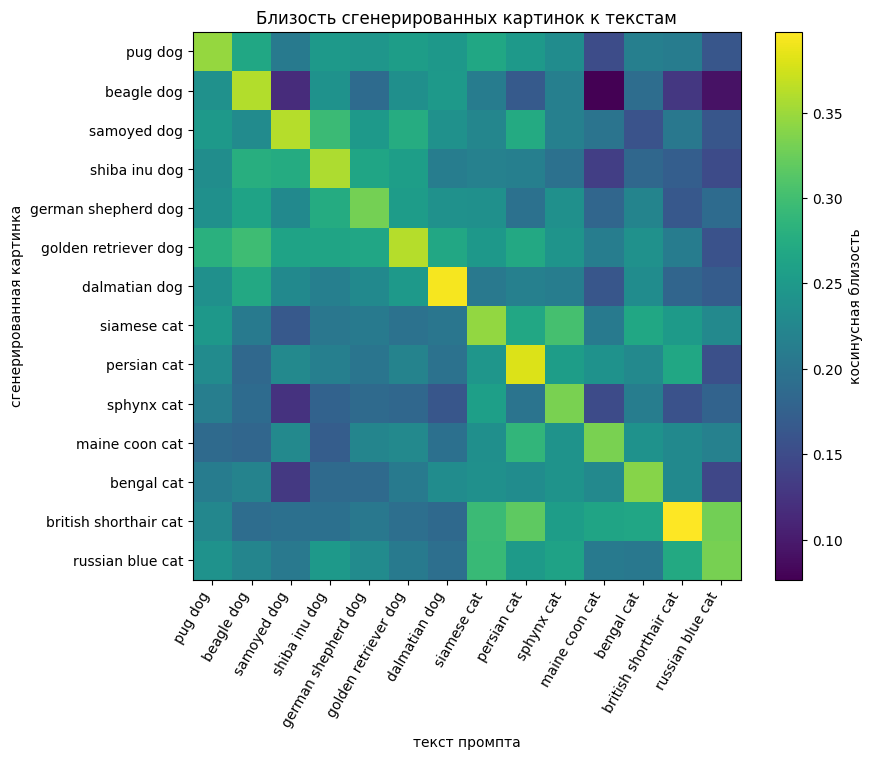

Картинок, которые CLIP относит к своему промпту: 14 из 14


In [17]:
with torch.no_grad():
    batch = torch.from_numpy(np.stack(generated_pets)).permute(0, 3, 1, 2).to(device)
    batch = clip_normalize(F.interpolate(batch, size=224, mode='bilinear', align_corners=False))
    image_features = F.normalize(clip_model.encode_image(batch), dim=-1)
    text_features = F.normalize(clip_model.encode_text(clip.tokenize(prompts).to(device)), dim=-1)
    similarity = (image_features @ text_features.T).cpu().numpy()

short = [p.replace('a photo of a ', '') for p in prompts]
plt.figure(figsize=(9, 7.5))
plt.imshow(similarity, cmap='viridis')
plt.xticks(range(len(short)), short, rotation=60, ha='right')
plt.yticks(range(len(short)), short)
plt.xlabel('текст промпта')
plt.ylabel('сгенерированная картинка')
plt.colorbar(label='косинусная близость')
plt.title('Близость сгенерированных картинок к текстам')
plt.tight_layout()
plt.show()

matched = int((similarity.argmax(1) == np.arange(len(prompts))).sum())
print(f'Картинок, которые CLIP относит к своему промпту: {matched} из {len(prompts)}')